# A Shared-Encoder Multi-Task Learning Framework for Simultaneous E-Commerce Attribute Inference

Predicting **product category**, **price tier**, and **customer sentiment** from a shared text encoder, compared against independent per-task baselines.

**Research question:** Does a shared-encoder multi-task learning approach provide useful advantages over separate machine-learning models for predicting product category, price tier, and customer sentiment?

Data: sample of the [Amazon Reviews 2023](https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023) dataset, acquired with strict storage budgeting (see `src/inspect_dataset.py`, `src/sample_dataset.py`, `src/join_metadata.py`).


## 1. Imports and configuration

In [1]:
import json, sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path('..').resolve()
sys.path.insert(0, str(ROOT / 'src'))

from model_utils import fit_price_thresholds, group_split, prepare_targets, leak_free_features
import pipeline

SEED = 20231010
np.random.seed(SEED)
print('seed:', SEED)
print('python', sys.version.split()[0])


seed: 20231010
python 3.13.5


## 2. Dataset loading and validation

Load the processed sample produced during the acquisition phase and re-run the core validation checks.

In [2]:
 # (dataset validation is run inline below)


In [3]:
df = pd.read_parquet('../data/processed/ecommerce_sample.parquet')
print('rows:', len(df), 'products:', df.product_id.nunique())
print(df.head(2).to_string(max_colwidth=60))

# core validation checks
required = ['product_id','product_title','product_description','category','price','review_text','rating','sentiment_label']
assert not [c for c in required if c not in df.columns], 'missing columns'
assert df.price.notna().all() and (df.price >= 0).all()
assert set(df.sentiment_label.unique()) <= {'negative','neutral','positive'}
assert df.review_text.notna().all()
print('validation: ALL PASS')


rows: 3383 products: 2361
   product_id                      product_title                                          product_description    category  price                                                  review_text  rating sentiment_label source_category                review_user_id  review_timestamp  review_verified_purchase  review_helpful_vote
0  B0BM4GX6TT  Looks good, but do your research!  Godefroy Professional Hair Color Tint Kit is ideal for c...  All Beauty  24.95  This product worked pretty well for me, but there was de...     4.0        positive      All_Beauty  AEAUSB24DTBTF3H2NFCIX2DXIJEA     1585776916730                      True                    0
1  B07W1WSJ9N                     Awesome Sauce!  Quality Over Quantity...; As artists, we don't have to s...  All Beauty  11.99  Love this handy roll and cutter! Perfect for lash lift a...     5.0        positive      All_Beauty  AEREA7CZPBXOGJQYRAFHE3QT6YOA     1579029674860                      True                    1

## 3. Preprocessing and target construction

Three classification targets:

- `category` - product main category (from metadata).
- `price_tier` - low/medium/high via **33rd/67th percentiles of the training split only**; same thresholds then applied unchanged to val/test (no re-fitting).
- `sentiment_label` - **rating-derived**: rating 1-2 = negative, 3 = neutral, 4-5 = positive. These are proxy labels from Amazon review scores, *not* independently annotated sentiment; this limitation is documented in the report.

Leakage rules enforced (see `src/model_utils.py`):
- sentiment inputs exclude `rating` and rating-derived features;
- price-tier inputs exclude `price` and any price-derived features;
- category inputs exclude the category label itself;
- TF-IDF vectorizers (and thresholds) are fit on training data only.

In [4]:
df, train, val, test, split_info = pipeline.load_split()
print(json.dumps(split_info, indent=1, default=str))
print('train/val/test sizes:', len(train), len(val), len(test))
print('no product overlap across splits:', split_info['no_overlap'])
print('price-tier thresholds (train-only):', split_info['thresholds'])


{
 "n_train": 2414,
 "n_val": 491,
 "n_test": 478,
 "train_products": 1653,
 "val_products": 354,
 "test_products": 354,
 "no_overlap": true,
 "seed": 20231010,
 "thresholds": {
  "t1": 14.253333333333332,
  "t2": 28.116666666666667,
  "method": "33rd/67th percentiles of train split",
  "degenerate": false
 },
 "grouped_categories": false
}
train/val/test sizes: 2414 491 478
no product overlap across splits: True
price-tier thresholds (train-only): {'t1': 14.253333333333332, 't2': 28.116666666666667, 'method': '33rd/67th percentiles of train split', 'degenerate': False}


## 4. Exploratory Data Analysis

saved figure: category_frequency.png - The three source categories dominate; minor labels come from meta main_category overlap.
saved figure: price_distribution.png - Prices are right-skewed; median ~20.0 USD, heavy right tail beyond ~50 USD.
saved figure: rating_sentiment.png - Ratings skew heavily to 5 stars; sentiment classes are imbalanced (80/15/5).
saved figure: review_length.png - Review lengths are also right-skewed; most reviews are short (< 50 words).
saved figure: category_vs_sentiment.png - Positive reviews dominate every category; negative share is highest in Health & Personal Care.
saved figure: price_vs_sentiment.png - Prices are similar across sentiment groups; no obvious price-sentiment relationship.
saved figure: price_tier_distribution.png - By construction (33/67 percentile thresholds), classes are nearly balanced; final thresholds are fit on train split only.
saved EDA figures -> ../results/figures (*.png), summary -> results/eda_summary.json


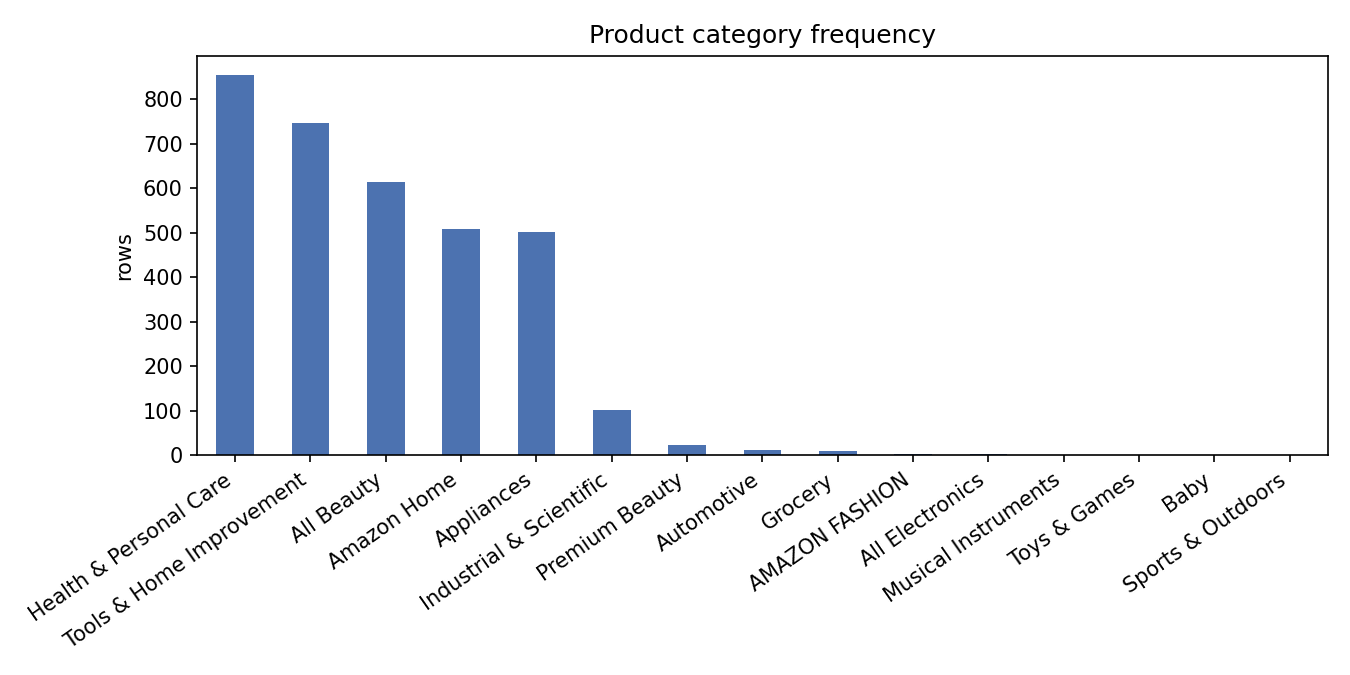

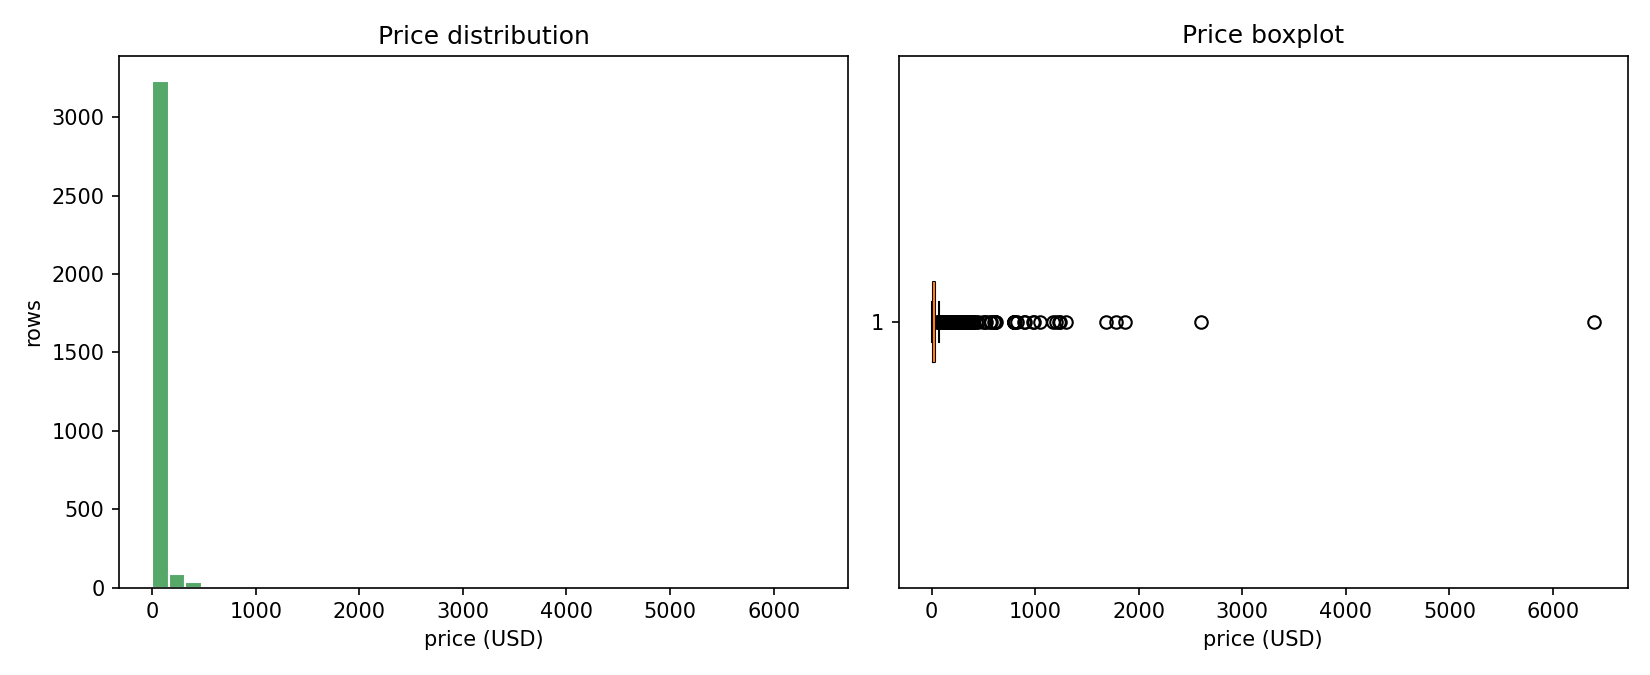

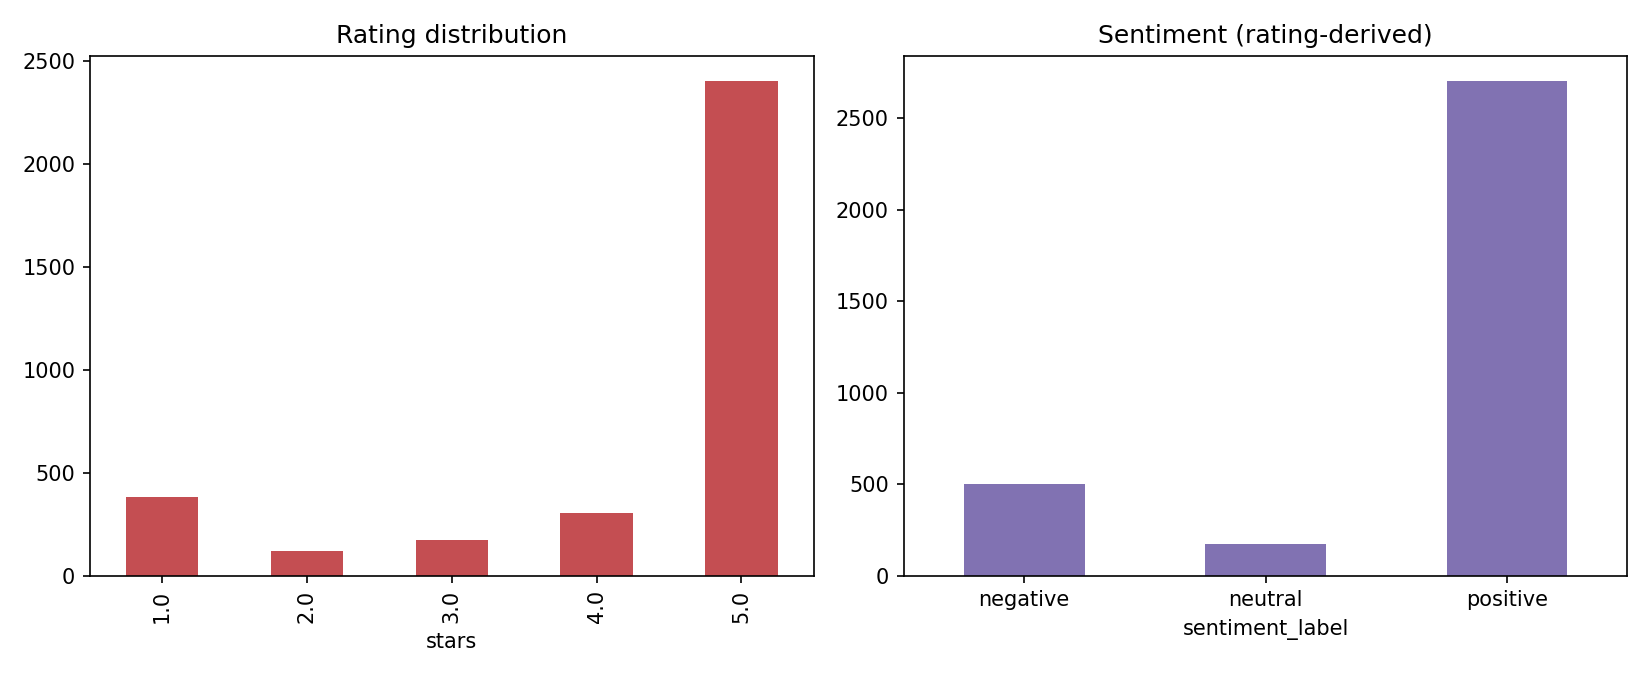

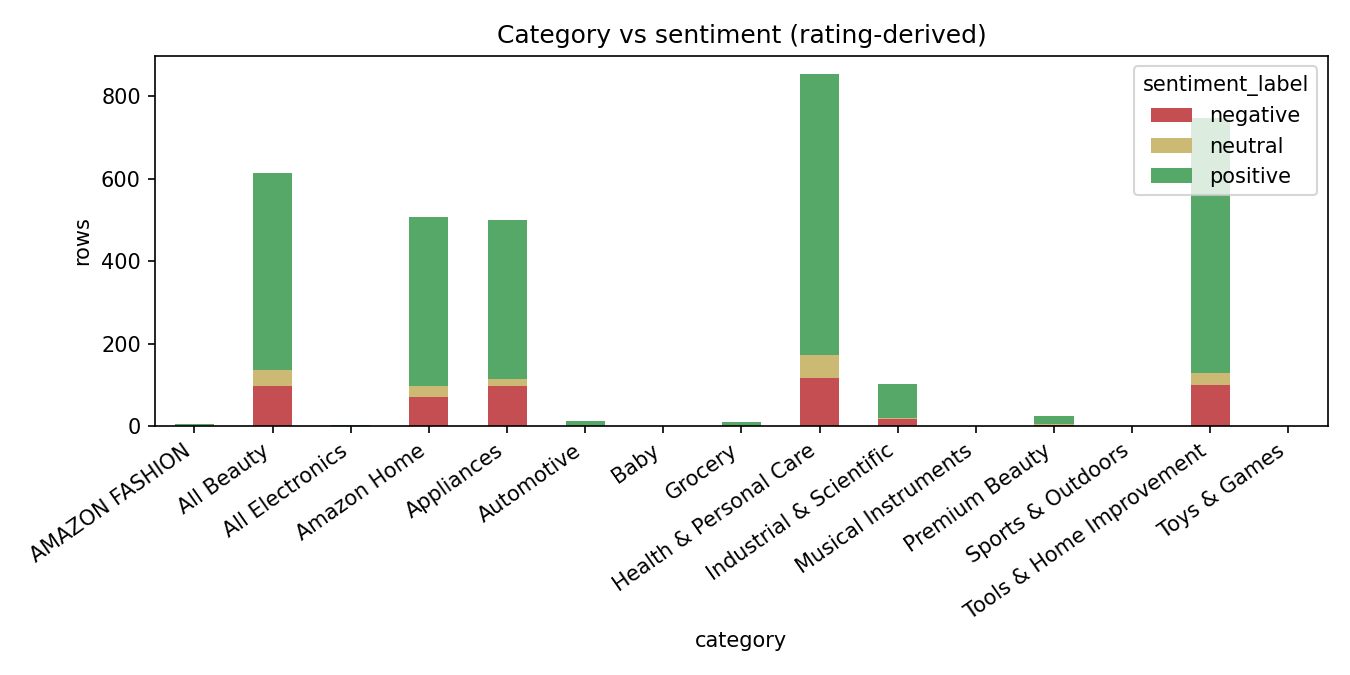

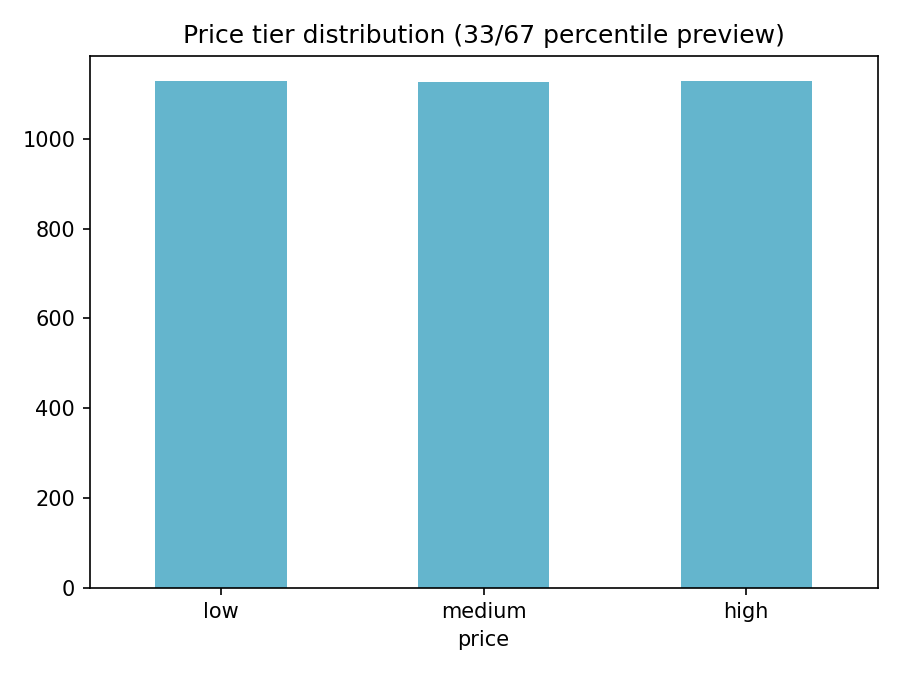

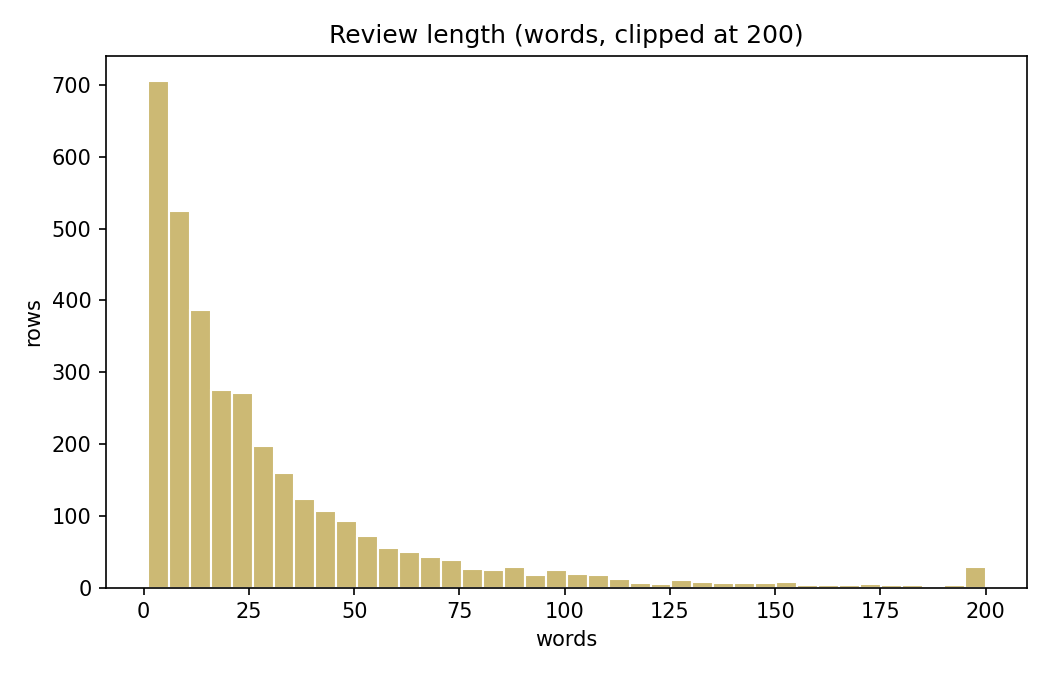

In [5]:
from analysis import run_eda, run_hypothesis_tests
import json
eda = run_eda(df)
Path('../results/eda_summary.json').write_text(json.dumps(eda, indent=1, default=str))
print('saved EDA figures -> ../results/figures (*.png), summary -> results/eda_summary.json')
# re-render a couple of key figures inline
from IPython.display import Image, display
for fig in ['category_frequency','price_distribution','rating_sentiment','category_vs_sentiment','price_tier_distribution','review_length']:
    display(Image(filename=f'../results/figures/{fig}.png'))


In [6]:
# key descriptive statistics
print('rows, cols:', df.shape)
print('missing values per column (non-zero):')
print(df.isna().sum()[lambda s: s > 0].to_string())
print('duplicate review_text rows:', int(df.review_text.duplicated().sum()))
print('products:', df.product_id.nunique(), '| categories:', df.category.nunique())
print('\ncategory counts:')
print(df.category.value_counts().to_string())
print('\nrating distribution:')
print(df.rating.value_counts().sort_index().to_string())
print('\nsentiment distribution:')
print(df.sentiment_label.value_counts().to_string())
print('\nprice summary:')
print(df.price.describe().round(3).to_string())


rows, cols: (3383, 14)
missing values per column (non-zero):
Series([], )
duplicate review_text rows: 116
products: 2361 | categories: 15

category counts:
category
Health & Personal Care      855
Tools & Home Improvement    748
All Beauty                  614
Amazon Home                 508
Appliances                  501
Industrial & Scientific     102
Premium Beauty               23
Automotive                   13
Grocery                       9
AMAZON FASHION                4
All Electronics               2
Musical Instruments           1
Toys & Games                  1
Baby                          1
Sports & Outdoors             1

rating distribution:
rating
1.0     383
2.0     119
3.0     175
4.0     304
5.0    2402

sentiment distribution:
sentiment_label
positive    2706
negative     502
neutral      175

price summary:
count    3383.000
mean       47.057
std       157.654
min         1.200
25%        12.000
50%        19.990
75%        35.990
max      6399.000


**Interpretation.** The dataset has 3,383 product-review pairs over 2,361 distinct products. Categories are dominated by Amazon Home, Tools & Home Improvement and Health & Personal Care with a long tail of rare meta labels; the rare labels make classification harder (test F1 macro is the metric that exposes this). Prices are right-skewed with a median around 20 USD - hence percentile-based price tiers. Ratings skew strongly positive (80% positive / 15% negative / 5% neutral), a well-known Amazon bias; macro-averaged metrics will be essential to fairly evaluate rare sentiment classes.

## 5. Statistical hypothesis testing

Two chi-square tests of independence:

- **H0a:** customer sentiment is independent of product category.
- **H0b:** customer sentiment is independent of price tier.

In [7]:
from analysis import run_hypothesis_tests
tests = run_hypothesis_tests(df)
Path('../results/hypothesis_tests.json').write_text(json.dumps(tests, indent=1))
print(json.dumps(tests, indent=1))


saved figure: h1_contingency.png - Observed counts; see hypothesis_tests.json for chi-square result.
{
 "H1_category_vs_sentiment": {
  "test": "H1: sentiment independent of product category",
  "status": "ok",
  "table_shape": [
   7,
   3
  ],
  "min_expected_cell": 2.8451078924031923,
  "chi2": 22.011846859815936,
  "dof": 12,
  "p_value": 0.03738725345274809,
  "cramers_v": 0.057037731520451475,
  "n": 3383
 },
 "H2_price_tier_vs_sentiment": {
  "test": "H2: sentiment independent of price tier",
  "status": "ok",
  "table_shape": [
   3,
   3
  ],
  "min_expected_cell": 57.05734555128584,
  "chi2": 8.582878429960072,
  "dof": 4,
  "p_value": 0.07241448411304957,
  "cramers_v": 0.03561643802648385,
  "n": 3383
 }
}


D:\Study Material\Sem 5\Data Science\LAB\Project\FDS_Final_Project\src\analysis.py:152: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  out.loc["Other (combined micro-categories)"] = other


**Interpretation (from the actual saved `results/hypothesis_tests.json`).**

- **H1 (sentiment ⊥ product category):** chi-square(12) = 22.01, p = 0.0374, Cramér's V = 0.057. At α = 0.05 we **reject H0**: a statistically significant but *weak* association exists. Note the sparse expected cells (min expected 2.85 after combining micro-categories), so this result should be treated cautiously.
- **H2 (sentiment ⊥ price tier):** chi-square(4) = 8.58, p = 0.0724, Cramér's V = 0.036. At α = 0.05 we **fail to reject H0**: no statistically significant association.

Neither test implies causation. Both effect sizes are small in practical terms.


## 6-10. Train/validation/test split + traditional baselines

Group-split at the product level so a product's reviews never span multiple splits.
Per task: LogisticRegression on TF-IDF (fit on train only) and a DecisionTree on a low-rank TF-IDF+SVD projection.

In [8]:
from baselines import run_baselines, results_frame
res = run_baselines(train, val, test, seed=SEED)
bres = results_frame(res)
bres.to_csv('../results/baseline_results.csv', index=False)
bres


,task,model,accuracy,precision_macro,recall_macro,f1_macro,train_seconds,n_train,n_test
0,category,decision_tree_test,0.4100,0.1357,0.1370,0.1334,0.23,2414,478
1,category,logreg_test,0.5732,0.2007,0.1921,0.1895,1.50,2905,478
2,category,logreg_val,0.6212,0.2105,0.2039,0.2035,0.67,2414,491
3,price_tier,decision_tree_test,0.3996,0.3981,0.3964,0.3941,0.29,2414,478
4,price_tier,logreg_test,0.4791,0.4707,0.4764,0.4724,0.45,2905,478
5,price_tier,logreg_val,0.4969,0.4948,0.4906,0.4911,0.21,2414,491
6,sentiment,decision_tree_test,0.7448,0.3917,0.4059,0.3987,0.23,2414,478
7,sentiment,logreg_test,0.8494,0.5708,0.4457,0.4691,0.26,2905,478
8,sentiment,logreg_val,0.8554,0.5588,0.4567,0.4795,0.15,2414,491


In [9]:
test_rows = bres[bres.model.str.contains('test')]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, task in zip(axes, ['category','price_tier','sentiment']):
    sub = test_rows[test_rows.task == task]
    ax.bar(sub.model.str.replace('_test',''), sub.f1_macro, color=['#4c72b0','#55a868'])
    ax.set_title(task)
    ax.set_ylim(0, 1)
    ax.set_ylabel('macro F1 (test)')
plt.tight_layout(); plt.savefig('../results/figures/baselines_f1.png', dpi=150); plt.show()


D:\YOLO_TEMP\ipykernel_46428\3660448797.py:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.savefig('../results/figures/baselines_f1.png', dpi=150); plt.show()


## 11-12. Shared-encoder multi-task model

TF-IDF (fit on train only) → 2-layer dense shared encoder (256→128, ReLU, dropout 0.2) → three linear heads (category, price tier, sentiment). Combined loss with equal task weights. Validation-used early model selection via mean macro-F1 across the three tasks.

In [10]:
from mtl_model import MTLConfig, train_mtl
cfg = MTLConfig(epochs=30, hidden_dims=(256,128), batch_size=64, lr=1e-3, seed=SEED)
mres = train_mtl(train, val, test, cfg)
print('train seconds:', round(mres.train_seconds,2))
print('model size KB:', round(mres.model_size_bytes/1024,1))
hist = pd.DataFrame(mres.history)
fig, ax = plt.subplots(figsize=(8,4))
for col in ['f1_category','f1_price_tier','f1_sentiment']:
    ax.plot(hist.epoch, hist[col], label=col)
ax.plot(hist.epoch, hist.mean_f1, '--', label='mean')
ax.set_xlabel('epoch'); ax.set_ylabel('macro F1 (val)'); ax.legend(); ax.set_title('MTL training curves')
plt.tight_layout(); plt.savefig('../results/figures/mtl_training_curves.png', dpi=150); plt.show()


train seconds: 5.21
model size KB: 5138.6


D:\YOLO_TEMP\ipykernel_46428\2748480161.py:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.savefig('../results/figures/mtl_training_curves.png', dpi=150); plt.show()


In [11]:
mtl_payload = {'test_metrics': mres.test_metrics, 'val_metrics_best': mres.val_metrics_best,
               'history': mres.history, 'config': mres.config, 'labels': mres.labels,
               'train_seconds': mres.train_seconds, 'model_size_bytes': mres.model_size_bytes,
               'confusions': mres.confusions}
Path('../results/mtl_results.json').write_text(json.dumps(mtl_payload, indent=1, default=str))
print(json.dumps(mres.test_metrics, indent=1))


{
 "category": {
  "accuracy": 0.4916317991631799,
  "precision_macro": 0.245400364206118,
  "recall_macro": 0.2538001817906378,
  "f1_macro": 0.24815537150471162
 },
 "price_tier": {
  "accuracy": 0.45188284518828453,
  "precision_macro": 0.45332453710465453,
  "recall_macro": 0.45257988065871757,
  "f1_macro": 0.4516060071615627
 },
 "sentiment": {
  "accuracy": 0.8410041841004184,
  "precision_macro": 0.5945917172362397,
  "recall_macro": 0.5405485521548328,
  "f1_macro": 0.5604628222412312
 }
}


## 13-14. Evaluation, comparative analysis, error analysis

In [12]:
rows = []
for _, r in test_rows.iterrows():
    rows.append({'task': r.task, 'model': r.model, 'accuracy': r.accuracy,
                 'precision_macro': r.precision_macro, 'recall_macro': r.recall_macro,
                 'f1_macro': r.f1_macro, 'train_seconds': r.train_seconds, 'model_size_KB': None})
for task, mm in mres.test_metrics.items():
    rows.append({'task': task, 'model': 'mtl_shared_encoder', 'accuracy': mm['accuracy'],
                 'precision_macro': mm['precision_macro'], 'recall_macro': mm['recall_macro'],
                 'f1_macro': mm['f1_macro'], 'train_seconds': mres.train_seconds,
                 'model_size_KB': round(mres.model_size_bytes/1024,1)})
cmp = pd.DataFrame(rows).sort_values(['task','model']).reset_index(drop=True)
cmp.to_csv('../results/comparison_results.csv', index=False)
cmp.round(4)


,task,model,accuracy,precision_macro,recall_macro,f1_macro,train_seconds,model_size_KB
0,category,decision_tree_test,0.4100,0.1357,0.1370,0.1334,0.2300,NaN
1,category,logreg_test,0.5732,0.2007,0.1921,0.1895,1.5000,NaN
2,category,mtl_shared_encoder,0.4916,0.2454,0.2538,0.2482,5.2125,5138.6
3,price_tier,decision_tree_test,0.3996,0.3981,0.3964,0.3941,0.2900,NaN
4,price_tier,logreg_test,0.4791,0.4707,0.4764,0.4724,0.4500,NaN
5,price_tier,mtl_shared_encoder,0.4519,0.4533,0.4526,0.4516,5.2125,5138.6
6,sentiment,decision_tree_test,0.7448,0.3917,0.4059,0.3987,0.2300,NaN
7,sentiment,logreg_test,0.8494,0.5708,0.4457,0.4691,0.2600,NaN
8,sentiment,mtl_shared_encoder,0.8410,0.5946,0.5405,0.5605,5.2125,5138.6


### Majority-class reference baselines

Because class frequencies differ across tasks (tier counts are near-balanced by construction; sentiment is 80/15/5; category has a long tail), a majority-class reference (mode of the TRAIN target, applied unchanged to val/test) shows what a no-signal model achieves.


In [13]:
import pipeline
mb = pipeline.majority_baselines(train, val, test)
maj_rows = []
for task in ['category', 'price_tier', 'sentiment']:
    r = mb[f'{task}__majority_test']
    maj_rows.append({
        'task': task,
        'model': f"majority_class({r['majority_class']})",
        'accuracy': r['accuracy'],
        'precision_macro': r['precision_macro'],
        'recall_macro': r['recall_macro'],
        'f1_macro': r['f1_macro'],
        'train_seconds': r['train_seconds'],
        'model_size_KB': 0.0
    })

# Deduplicate the existing model rows before appending the three majority baselines.
# Do not mutate the `rows` list used to construct the original comparison table.
cmp = cmp.drop_duplicates(subset=['task', 'model'], keep='first').copy()
maj_df = pd.DataFrame(maj_rows)
cmp = (pd.concat([cmp, maj_df], ignore_index=True)
       .drop_duplicates(subset=['task', 'model'], keep='first')
       .sort_values(['task', 'model'])
       .reset_index(drop=True))
cmp.to_csv('../results/comparison_results.csv', index=False)
cmp.round(4)

,task,model,accuracy,precision_macro,recall_macro,f1_macro,train_seconds,model_size_KB
0,category,decision_tree_test,0.4100,0.1357,0.1370,0.1334,0.2300,NaN
1,category,logreg_test,0.5732,0.2007,0.1921,0.1895,1.5000,NaN
2,category,majority_class(Health & Personal Care),0.2092,0.0174,0.0833,0.0288,0.0000,0.0
3,category,mtl_shared_encoder,0.4916,0.2454,0.2538,0.2482,5.2125,5138.6
4,price_tier,decision_tree_test,0.3996,0.3981,0.3964,0.3941,0.2900,NaN
5,price_tier,logreg_test,0.4791,0.4707,0.4764,0.4724,0.4500,NaN
6,price_tier,majority_class(low),0.2971,0.0990,0.3333,0.1527,0.0000,0.0
7,price_tier,mtl_shared_encoder,0.4519,0.4533,0.4526,0.4516,5.2125,5138.6
8,sentiment,decision_tree_test,0.7448,0.3917,0.4059,0.3987,0.2300,NaN
9,sentiment,logreg_test,0.8494,0.5708,0.4457,0.4691,0.2600,NaN


### Grouped rare categories (leakage-safe re-run)

Categories with < 30 TRAIN-split rows are relabeled 'Other' in all splits (rule decided from train data only). Models are re-run consistently under this grouped label space.


In [14]:
df_g, train_g, val_g, test_g, info_g = pipeline.load_split(group_categories=True)
from baselines import run_baselines, results_frame
res_g = run_baselines(train_g, val_g, test_g, seed=SEED)
bres_g = results_frame(res_g)
from mtl_model import MTLConfig
mres_g = train_mtl(train_g, val_g, test_g, MTLConfig(epochs=30, hidden_dims=(256,128), batch_size=64, lr=1e-3, seed=SEED), save_checkpoint=False)

# only the grouped logreg test rows for the grouped-variant table
grows = []
for _, r in bres_g[bres_g.model.str.contains('test')].iterrows():
    grows.append({'task': r.task, 'model': r.model, 'accuracy': r.accuracy,
                  'precision_macro': r.precision_macro, 'recall_macro': r.recall_macro,
                  'f1_macro': r.f1_macro, 'train_seconds': r.train_seconds, 'model_size_KB': None})
for task, mm in mres_g.test_metrics.items():
    grows.append({'task': task, 'model': 'mtl_shared_encoder', 'accuracy': mm['accuracy'],
                  'precision_macro': mm['precision_macro'], 'recall_macro': mm['recall_macro'],
                  'f1_macro': mm['f1_macro'], 'train_seconds': mres_g.train_seconds,
                  'model_size_KB': round(mres_g.model_size_bytes/1024,1)})
cmp_g = pd.DataFrame(grows).sort_values(['task','model']).reset_index(drop=True)
cmp_g.to_csv('../results/comparison_grouped.csv', index=False)
Path('../results/mtl_grouped_results.json').write_text(json.dumps(
    {'test_metrics': mres_g.test_metrics, 'confusions': mres_g.confusions, 'labels': mres_g.labels,
     'grouping_rule': info_g['grouped_categories']}, indent=1, default=str))
print('category rows after grouping:', train_g.category.value_counts().to_dict())
cmp_g.round(4)


category rows after grouping: {'Health & Personal Care': 625, 'Tools & Home Improvement': 498, 'All Beauty': 452, 'Amazon Home': 370, 'Appliances': 358, 'Industrial & Scientific': 79, 'Other': 32}


,task,model,accuracy,precision_macro,recall_macro,f1_macro,train_seconds,model_size_KB
0,category,decision_tree_test,0.4100,0.2918,0.2936,0.2864,0.2400,NaN
1,category,logreg_test,0.5774,0.4326,0.4151,0.4097,0.7800,NaN
2,category,mtl_shared_encoder,0.4833,0.3374,0.3529,0.3440,4.4053,5136.1
3,price_tier,decision_tree_test,0.3996,0.3981,0.3964,0.3941,0.2300,NaN
4,price_tier,logreg_test,0.4791,0.4707,0.4764,0.4724,0.3800,NaN
5,price_tier,mtl_shared_encoder,0.4456,0.4435,0.4434,0.4434,4.4053,5136.1
6,sentiment,decision_tree_test,0.7448,0.3917,0.4059,0.3987,0.2300,NaN
7,sentiment,logreg_test,0.8494,0.5708,0.4457,0.4691,0.3600,NaN
8,sentiment,mtl_shared_encoder,0.8556,0.6314,0.5282,0.5629,4.4053,5136.1


In [15]:
# confusion matrices for the MTL model
import numpy as np
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, task in zip(axes, ['category','price_tier','sentiment']):
    cm = np.array(mres.confusions[task])
    im = ax.imshow(cm, cmap='Blues')
    ax.set_title(task)
    ax.set_xlabel('predicted'); ax.set_ylabel('true')
    labels = mres.labels[task]
    if len(labels) <= 8:
        ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=45, ha='right', fontsize=7)
        ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels, fontsize=7)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, str(cm[i,j]), ha='center', va='center', fontsize=7, color='orange' if cm[i,j]>0 else 'white')
plt.tight_layout(); plt.savefig('../results/figures/mtl_confusions.png', dpi=150); plt.show()


D:\YOLO_TEMP\ipykernel_46428\3889162884.py:16: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.savefig('../results/figures/mtl_confusions.png', dpi=150); plt.show()


In [16]:
# Error analysis: use one row per task/model from the authoritative comparison table.
cmp_unique = cmp.drop_duplicates(subset=['task', 'model'], keep='first')
worst = (cmp_unique[cmp_unique.model == 'mtl_shared_encoder']
         .set_index('task')[['f1_macro', 'accuracy']])
print('MTL per-task test performance:')
print(worst.round(4).to_string())

gg_unique = cmp_g.drop_duplicates(subset=['task', 'model'], keep='first')
print('\nGrouped-category MTL macro-F1:')
print(gg_unique[gg_unique.model == 'mtl_shared_encoder']
      .set_index('task')['f1_macro'].round(4).to_string())

print('\nObservations:')
print('- Original-label category macro-F1 is 0.2482 for MTL; grouped-label category macro-F1 is 0.3440.')
print('- Under grouped labels, logistic regression reaches category macro-F1 0.4100, above MTL at 0.3440.')
print('- Price-tier macro-F1 is lower for MTL than logistic regression in both experiments.')
print('- Sentiment macro-F1 is higher for MTL than logistic regression in both experiments.')
print('- Results depend on the task and label space; MTL is not uniformly superior.')

MTL per-task test performance:
            f1_macro  accuracy
task                          
category      0.2482    0.4916
price_tier    0.4516    0.4519
sentiment     0.5605    0.8410

Grouped-category MTL macro-F1:
task
category      0.3440
price_tier    0.4434
sentiment     0.5629

Observations:
- Original-label category macro-F1 is 0.2482 for MTL; grouped-label category macro-F1 is 0.3440.
- Under grouped labels, logistic regression reaches category macro-F1 0.4100, above MTL at 0.3440.
- Price-tier macro-F1 is lower for MTL than logistic regression in both experiments.
- Sentiment macro-F1 is higher for MTL than logistic regression in both experiments.
- Results depend on the task and label space; MTL is not uniformly superior.


In [17]:
# Auto-generated findings from deduplicated, authoritative comparison tables.
from IPython.display import Markdown, display

g = cmp.drop_duplicates(['task', 'model']).set_index(['task', 'model'])
gg = cmp_g.drop_duplicates(['task', 'model']).set_index(['task', 'model'])
rows_find = []
for task in ['category', 'price_tier', 'sentiment']:
    b = float(g.loc[(task, 'logreg_test'), 'f1_macro'])
    m = float(g.loc[(task, 'mtl_shared_encoder'), 'f1_macro'])
    mg = float(gg.loc[(task, 'mtl_shared_encoder'), 'f1_macro'])
    bg = float(gg.loc[(task, 'logreg_test'), 'f1_macro'])
    verdict = 'MTL higher' if m > b else ('Logistic Regression higher' if m < b else 'tie')
    rows_find.append(
        f"- **{task} (original labels):** Logistic Regression macro-F1={b:.4f}; "
        f"MTL macro-F1={m:.4f} ({verdict}). "
        f"**Grouped-category experiment:** Logistic Regression macro-F1={bg:.4f}; "
        f"MTL macro-F1={mg:.4f}."
    )
display(Markdown('\n'.join(rows_find)))

- **category (original labels):** Logistic Regression macro-F1=0.1895; MTL macro-F1=0.2482 (MTL higher). **Grouped-category experiment:** Logistic Regression macro-F1=0.4097; MTL macro-F1=0.3440.
- **price_tier (original labels):** Logistic Regression macro-F1=0.4724; MTL macro-F1=0.4516 (Logistic Regression higher). **Grouped-category experiment:** Logistic Regression macro-F1=0.4724; MTL macro-F1=0.4434.
- **sentiment (original labels):** Logistic Regression macro-F1=0.4691; MTL macro-F1=0.5605 (MTL higher). **Grouped-category experiment:** Logistic Regression macro-F1=0.4691; MTL macro-F1=0.5629.

## 15. Stage 1 findings, limitations, and Stage 2

**Stage 1 findings.** The shared TF-IDF encoder does not outperform independent baselines uniformly. Sentiment is the strongest MTL result; price-tier performance is slightly below Logistic Regression, and category results depend on whether rare categories are grouped. See the comparison tables above for the actual values.

**Stage 2.** The following section adds a shared DistilBERT encoder with three task-specific classification heads. Its training/evaluation cells are a reproducible experiment definition, not precomputed evidence. Run them in the project environment to download pretrained model weights, fine-tune on the existing grouped product split, save a checkpoint, and produce Stage 1-versus-Stage 2 metrics. No transformer score should be reported until the run completes.

**Limitations.**
- Sample size is 3,383 product-review pairs and the sampled source coverage is limited.
- Sentiment labels are rating-derived proxies, not independent human annotations.
- Price tiers are inferred from text that may contain little reliable price information.
- Rare categories are grouped using a train-only rule (<30 TRAIN rows -> `Other`) in the grouped experiment.
- Range-probe sampling is not exactly uniform over entire source files.
- Cumulative network download volume was recorded as 5.12 GB, exceeding the 4.5 GB download budget; the local dataset footprint was about 149.9 MB.
- Statistical tests include sparse expected cells, so the category/sentiment association should be interpreted cautiously.

## Stage 2 — Shared-transformer multi-task learning (DistilBERT)

This section extends Stage 1 rather than replacing it. It uses one pretrained DistilBERT encoder shared by three classification heads (category, price tier, sentiment), trained with the sum of the three cross-entropy losses. It reuses the existing processed dataset and product-grouped split; it does **not** download the dataset again.

**Evaluation protocol:** the rare-category grouped label space is used for this transformer experiment so every target has a stable label space. Validation macro-F1 selects the checkpoint; the held-out test split is evaluated only after training. Results are saved separately under `results/transformer_mtl_*` and compared with the grouped Stage 1 baselines. No Stage 2 score is claimed until these cells are run successfully in the project environment.

**Compute note:** install `transformers` if it is not already available (`pip install transformers`). The first model load downloads the pretrained DistilBERT weights. On a 6 GB VRAM GPU, start with batch size 8 and max sequence length 128. If CUDA runs out of memory, reduce batch size to 4. This stage is intentionally not executed automatically while editing the notebook, so no unverified result is added to the report.

In [ ]:
# Stage 2 setup: shared DistilBERT encoder with three task-specific heads.
# Requires: pip install transformers
# This cell reuses the existing processed sample; it does not reacquire the dataset.

import json, time, random
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

STAGE2_MODEL_NAME = "distilbert-base-uncased"
STAGE2_MAX_LENGTH = 128
STAGE2_BATCH_SIZE = 8
STAGE2_EPOCHS = 3
STAGE2_LR = 2e-5
STAGE2_SEED = SEED

random.seed(STAGE2_SEED)
np.random.seed(STAGE2_SEED)
torch.manual_seed(STAGE2_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(STAGE2_SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)
print("model:", STAGE2_MODEL_NAME)

# Use the existing leakage-safe rare-category grouping rule for a stable label space.
df_t, train_t, val_t, test_t, split_info_t = pipeline.load_split(group_categories=True)
assert split_info_t.get("no_overlap", False), "Product overlap detected across splits"

TEXT_COLS = ["product_title", "product_description", "review_text"]
TASKS = ["category", "price_tier", "sentiment"]

def make_text(frame):
    # Never include raw price, rating, category labels, or target-derived fields in the input.
    parts = []
    for col in TEXT_COLS:
        if col in frame.columns:
            parts.append(frame[col].fillna("").astype(str).str.strip())
        else:
            parts.append(pd.Series("", index=frame.index, dtype=str))
    return (parts[0] + ". " + parts[1] + ". " + parts[2]).str.slice(0, 12000).tolist()

# Labels are encoded from the grouped training label space; unseen labels are mapped to Other
# for category and rejected for the other tasks (which should have fixed target vocabularies).
label_maps = {}
for task in TASKS:
    labels = sorted(train_t[task].astype(str).unique().tolist())
    if task == "category" and "Other" not in labels:
        labels.append("Other")
    label_maps[task] = {label: idx for idx, label in enumerate(labels)}

def encode_frame(frame):
    texts = make_text(frame)
    ys = {}
    for task in TASKS:
        vals = frame[task].astype(str)
        if task == "category":
            vals = vals.where(vals.isin(label_maps[task]), "Other")
        unknown = sorted(set(vals) - set(label_maps[task]))
        if unknown:
            raise ValueError(f"Unexpected labels for {task}: {unknown}")
        ys[task] = np.asarray([label_maps[task][v] for v in vals], dtype=np.int64)
    return texts, ys

train_texts, train_y = encode_frame(train_t)
val_texts, val_y = encode_frame(val_t)
test_texts, test_y = encode_frame(test_t)

tokenizer = AutoTokenizer.from_pretrained(STAGE2_MODEL_NAME)

class MultiTaskTextDataset(Dataset):
    def __init__(self, texts, targets):
        self.enc = tokenizer(
            texts, truncation=True, padding="max_length",
            max_length=STAGE2_MAX_LENGTH, return_tensors="pt"
        )
        self.targets = {k: torch.tensor(v, dtype=torch.long) for k, v in targets.items()}
    def __len__(self):
        return len(self.targets[TASKS[0]])
    def __getitem__(self, idx):
        item = {k: v[idx] for k, v in self.enc.items()}
        item.update({f"y_{k}": self.targets[k][idx] for k in TASKS})
        return item

train_loader = DataLoader(MultiTaskTextDataset(train_texts, train_y),
                          batch_size=STAGE2_BATCH_SIZE, shuffle=True)
val_loader = DataLoader(MultiTaskTextDataset(val_texts, val_y),
                        batch_size=STAGE2_BATCH_SIZE, shuffle=False)
test_loader = DataLoader(MultiTaskTextDataset(test_texts, test_y),
                         batch_size=STAGE2_BATCH_SIZE, shuffle=False)

class DistilBertMultiTask(nn.Module):
    def __init__(self, model_name, task_sizes):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(model_name)
        hidden = self.encoder.config.hidden_size
        self.dropout = nn.Dropout(0.2)
        self.heads = nn.ModuleDict({task: nn.Linear(hidden, n) for task, n in task_sizes.items()})
    def forward(self, input_ids, attention_mask):
        out = self.encoder(input_ids=input_ids, attention_mask=attention_mask)
        pooled = self.dropout(out.last_hidden_state[:, 0])
        return {task: head(pooled) for task, head in self.heads.items()}

task_sizes = {task: len(label_maps[task]) for task in TASKS}
model_t = DistilBertMultiTask(STAGE2_MODEL_NAME, task_sizes).to(device)
optimizer_t = torch.optim.AdamW(model_t.parameters(), lr=STAGE2_LR)
loss_fn_t = nn.CrossEntropyLoss()
use_amp = device.type == "cuda"
scaler_t = torch.amp.GradScaler("cuda", enabled=use_amp)

def run_eval(loader, include_predictions=False):
    model_t.eval()
    ys_all = {task: [] for task in TASKS}
    pred_all = {task: [] for task in TASKS}
    total_loss, n_batches = 0.0, 0
    with torch.no_grad():
        for batch in loader:
            batch = {k: v.to(device) for k, v in batch.items()}
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                logits = model_t(batch["input_ids"], batch["attention_mask"])
                loss = sum(loss_fn_t(logits[t], batch[f"y_{t}"]) for t in TASKS)
            total_loss += float(loss.item()); n_batches += 1
            for task in TASKS:
                ys_all[task].extend(batch[f"y_{task}"].cpu().numpy().tolist())
                pred_all[task].extend(logits[task].argmax(dim=1).cpu().numpy().tolist())
    metrics = {}
    for task in TASKS:
        p, r, f1, _ = precision_recall_fscore_support(
            ys_all[task], pred_all[task], average="macro", zero_division=0
        )
        metrics[task] = {
            "accuracy": float(accuracy_score(ys_all[task], pred_all[task])),
            "precision_macro": float(p), "recall_macro": float(r), "f1_macro": float(f1)
        }
    metrics["mean_macro_f1"] = float(np.mean([metrics[t]["f1_macro"] for t in TASKS]))
    metrics["loss"] = total_loss / max(n_batches, 1)
    if include_predictions:
        metrics["labels"] = ys_all
        metrics["predictions"] = pred_all
    return metrics

stage2_history = []
best_val_f1 = -1.0
best_state = None
stage2_start = time.time()

for epoch in range(1, STAGE2_EPOCHS + 1):
    model_t.train()
    running_loss, n_batches = 0.0, 0
    for batch in train_loader:
        batch = {k: v.to(device) for k, v in batch.items()}
        optimizer_t.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            logits = model_t(batch["input_ids"], batch["attention_mask"])
            loss = sum(loss_fn_t(logits[t], batch[f"y_{t}"]) for t in TASKS)
        scaler_t.scale(loss).backward()
        scaler_t.step(optimizer_t)
        scaler_t.update()
        running_loss += float(loss.item()); n_batches += 1

    val_metrics = run_eval(val_loader)
    record = {
        "epoch": epoch,
        "train_loss": running_loss / max(n_batches, 1),
        "val_loss": val_metrics["loss"],
        "val_mean_macro_f1": val_metrics["mean_macro_f1"],
        **{f"val_{task}_macro_f1": val_metrics[task]["f1_macro"] for task in TASKS}
    }
    stage2_history.append(record)
    print(record)
    if val_metrics["mean_macro_f1"] > best_val_f1:
        best_val_f1 = val_metrics["mean_macro_f1"]
        best_state = {k: v.detach().cpu().clone() for k, v in model_t.state_dict().items()}

assert best_state is not None, "No model checkpoint was selected"
model_t.load_state_dict(best_state)
stage2_train_seconds = time.time() - stage2_start

# Evaluate test only after selecting the best checkpoint on validation macro-F1.
stage2_test_metrics = run_eval(test_loader, include_predictions=True)
stage2_summary = {
    "model_name": STAGE2_MODEL_NAME,
    "architecture": "shared DistilBERT encoder + category/price_tier/sentiment heads",
    "max_length": STAGE2_MAX_LENGTH,
    "batch_size": STAGE2_BATCH_SIZE,
    "epochs_requested": STAGE2_EPOCHS,
    "best_validation_mean_macro_f1": best_val_f1,
    "train_seconds": stage2_train_seconds,
    "device": str(device),
    "grouped_category_split": True,
    "split_info": split_info_t,
    "label_maps": label_maps,
    "history": stage2_history,
    "test_metrics": {task: stage2_test_metrics[task] for task in TASKS}
}
out_dir = Path("../results")
model_dir = Path("../data/models")
out_dir.mkdir(parents=True, exist_ok=True)
model_dir.mkdir(parents=True, exist_ok=True)
(out_dir / "transformer_mtl_results.json").write_text(json.dumps(stage2_summary, indent=2))
pd.DataFrame(stage2_history).to_csv(out_dir / "transformer_mtl_history.csv", index=False)
torch.save({
    "model_state_dict": model_t.state_dict(),
    "model_name": STAGE2_MODEL_NAME,
    "label_maps": label_maps,
    "max_length": STAGE2_MAX_LENGTH,
    "task_sizes": task_sizes,
}, model_dir / "distilbert_mtl_best.pt")
tokenizer.save_pretrained(model_dir / "distilbert_mtl_tokenizer")
print(json.dumps(stage2_summary["test_metrics"], indent=2))
print("saved checkpoint:", model_dir / "distilbert_mtl_best.pt")
print("saved results:", out_dir / "transformer_mtl_results.json")

### Stage 2 comparison with Stage 1

Run the transformer training cell above first. This comparison reads the saved grouped-label Stage 1 results and the Stage 2 test metrics; it intentionally fails with a clear message if the Stage 2 results file does not exist. Compare macro-F1 as the primary metric because the targets are imbalanced.

In [ ]:
from pathlib import Path
import json
import pandas as pd

stage1_path = Path("../results/comparison_grouped.csv")
stage2_path = Path("../results/transformer_mtl_results.json")
if not stage1_path.exists():
    raise FileNotFoundError(f"Stage 1 grouped comparison not found: {stage1_path}")
if not stage2_path.exists():
    raise FileNotFoundError(
        "Run the Stage 2 DistilBERT training cell first; no transformer results are being fabricated."
    )

stage1 = pd.read_csv(stage1_path)
stage2 = json.loads(stage2_path.read_text())
stage2_rows = []
for task in ["category", "price_tier", "sentiment"]:
    m = stage2["test_metrics"][task]
    stage2_rows.append({
        "task": task, "model": "DistilBERT shared encoder",
        "accuracy": m["accuracy"], "precision_macro": m["precision_macro"],
        "recall_macro": m["recall_macro"], "f1_macro": m["f1_macro"]
    })
stage2_df = pd.DataFrame(stage2_rows)
stage1_keep = stage1[stage1["model"].isin(["logreg_test", "mtl_shared_encoder"])][
    ["task", "model", "accuracy", "precision_macro", "recall_macro", "f1_macro"]
]
stage_compare = pd.concat([stage1_keep, stage2_df], ignore_index=True)
stage_compare = stage_compare.sort_values(["task", "model"]).reset_index(drop=True)
stage_compare.to_csv("../results/stage1_stage2_comparison.csv", index=False)
stage_compare.round(4)